In [ ]:
import pandas as pd

In [ ]:
!pip install openpyxl

In [ ]:
df=pd.read_excel('PJMW_MW_Hourly.xlsx',parse_dates=['Datetime'])

In [ ]:
df.head()

,Datetime,PJMW_MW
0,2002-12-31 01:00:00,5077
1,2002-12-31 02:00:00,4939
2,2002-12-31 03:00:00,4885
3,2002-12-31 04:00:00,4857
4,2002-12-31 05:00:00,4930


# EDA

## Exploring Data

In [ ]:
# shape of data
df.shape

(143206, 2)

In [ ]:
# summary of data
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 143206 entries, 0 to 143205
Data columns (total 2 columns):
 #   Column    Non-Null Count   Dtype         
---  ------    --------------   -----         
 0   Datetime  143206 non-null  datetime64[ns]
 1   PJMW_MW   143206 non-null  int64         
dtypes: datetime64[ns](1), int64(1)
memory usage: 2.2 MB


## Data Cleaning

In [ ]:
# sorting data according to timestamps to preserve chronology
df.sort_values(by='Datetime',inplace=True)

In [ ]:
df.head()

,Datetime,PJMW_MW
6574,2002-04-01 01:00:00,4374
6575,2002-04-01 02:00:00,4306
6576,2002-04-01 03:00:00,4322
6577,2002-04-01 04:00:00,4359
6578,2002-04-01 05:00:00,4436


In [ ]:
# check for nulls
df.isna().sum()

,0
Datetime,0
PJMW_MW,0


Thus we can see that no null values can be seen in this dataset.

In [ ]:
# set datetime as index
df.set_index('Datetime',inplace=True)

In [ ]:
df.head()

,PJMW_MW
Datetime,
2002-04-01 01:00:00,4374
2002-04-01 02:00:00,4306
2002-04-01 03:00:00,4322
2002-04-01 04:00:00,4359
2002-04-01 05:00:00,4436


In [ ]:
# checking for duplicate indexes
df.index.duplicated().sum()

np.int64(4)

In [ ]:
# dropping duplicate indexes
df=df[~df.index.duplicated()]

In [ ]:
# checking for any missing timestamps
full_range = pd.date_range(start=df.index.min(), end=df.index.max(), freq='h')
df = df.reindex(full_range)

In [ ]:
# after filling missing timestamps lets check for nulls again
df.isna().sum()

,0
PJMW_MW,30


In [ ]:
df.interpolate(method='linear',inplace=True)

In [ ]:
# checking for nulls after interpolation
df.isna().sum()

,0
PJMW_MW,0


In [ ]:
df.index.freq='h'

In [ ]:
df.tail()

,PJMW_MW
2018-08-02 20:00:00,6545.0
2018-08-02 21:00:00,6496.0
2018-08-02 22:00:00,6325.0
2018-08-02 23:00:00,5892.0
2018-08-03 00:00:00,5489.0


## Visualizations

In [ ]:
# Extract Time Features
df['Hour'] = df.index.hour
df['DayOfWeek'] = df.index.dayofweek
df['Month'] = df.index.month
df['Year'] = df.index.year
df['DayName'] = df.index.day_name()

In [ ]:
df.head()

,PJMW_MW,Hour,DayOfWeek,Month,Year,DayName
2002-04-01 01:00:00,4374.0,1,0,4,2002,Monday
2002-04-01 02:00:00,4306.0,2,0,4,2002,Monday
2002-04-01 03:00:00,4322.0,3,0,4,2002,Monday
2002-04-01 04:00:00,4359.0,4,0,4,2002,Monday
2002-04-01 05:00:00,4436.0,5,0,4,2002,Monday


In [ ]:
# Function to obtain seasons
def get_season(month):
    if month in [12, 1, 2]:
        return 'Winter'
    elif month in [3, 4, 5]:
        return 'Summer (Dry/Pre-Monsoon)'
    elif month in [6, 7, 8, 9]:
        return 'Rainy (Monsoon)'
    else:
        return 'Autumn (Post-Monsoon)'

In [ ]:
df['Season'] = df['Month'].apply(get_season)

In [ ]:
df.head()

,PJMW_MW,Hour,DayOfWeek,Month,Year,DayName,Season
2002-04-01 01:00:00,4374.0,1,0,4,2002,Monday,Summer (Dry/Pre-Monsoon)
2002-04-01 02:00:00,4306.0,2,0,4,2002,Monday,Summer (Dry/Pre-Monsoon)
2002-04-01 03:00:00,4322.0,3,0,4,2002,Monday,Summer (Dry/Pre-Monsoon)
2002-04-01 04:00:00,4359.0,4,0,4,2002,Monday,Summer (Dry/Pre-Monsoon)
2002-04-01 05:00:00,4436.0,5,0,4,2002,Monday,Summer (Dry/Pre-Monsoon)


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

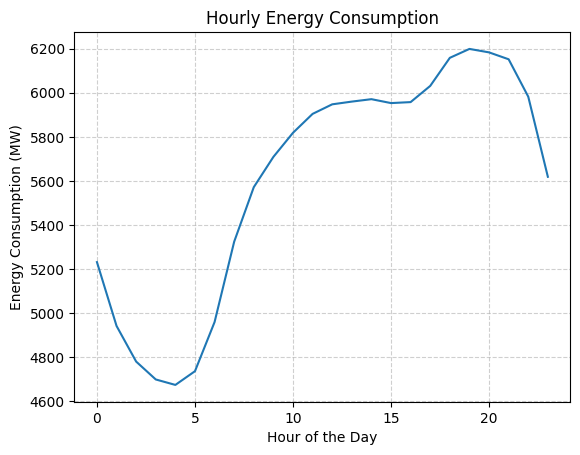

In [ ]:
# Hourly energy consumption trend
sns.lineplot(data=df, x='Hour', y='PJMW_MW', errorbar=None)
plt.title('Hourly Energy Consumption')
plt.xlabel('Hour of the Day')
plt.ylabel('Energy Consumption (MW)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

By oberserving the energy consumption trend we can conclude that the energy consumption peaks after afternoon.

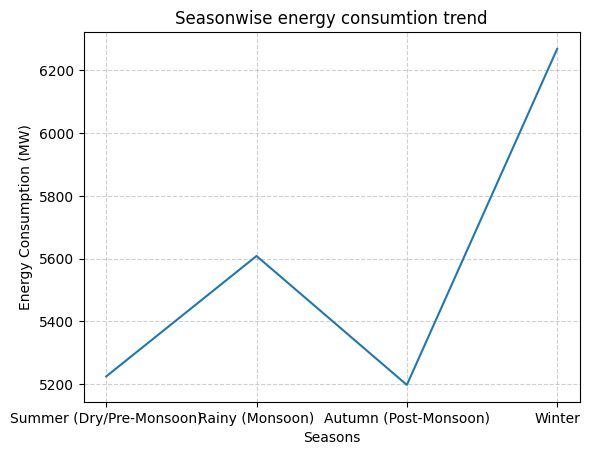

In [ ]:
# Seasonwise energy consumption trend
sns.lineplot(data=df, x='Season', y='PJMW_MW', errorbar=None)
plt.title('Seasonwise energy consumtion trend')
plt.xlabel('Seasons')
plt.ylabel('Energy Consumption (MW)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

By observing energy consumption trend throughout year we can conclude that energy consumption peaks during winter season.

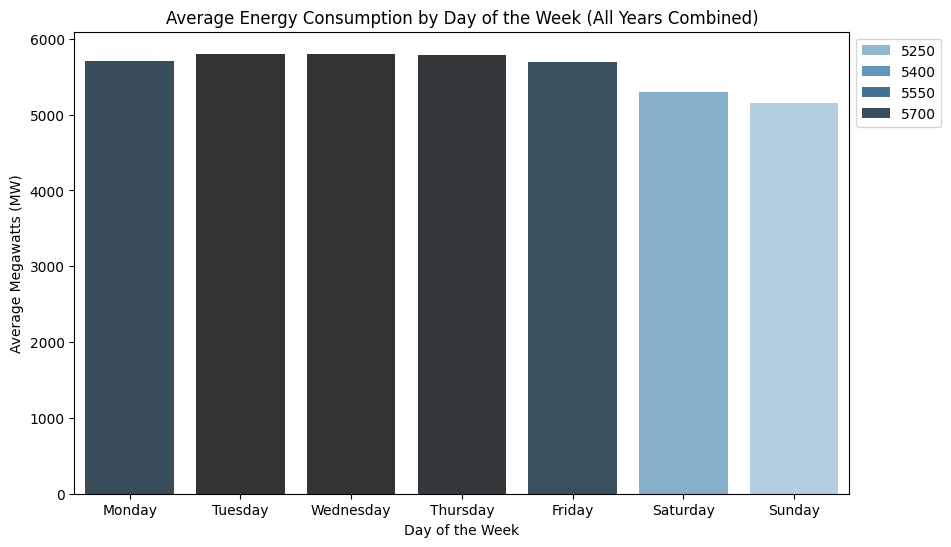

In [ ]:
# Weekly energy consumption
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']

dow_avg = df.groupby('DayName')['PJMW_MW'].mean().reindex(day_order).reset_index()

plt.figure(figsize=(10, 6))
sns.barplot(data=dow_avg, x='DayName', y='PJMW_MW',hue='PJMW_MW', palette='Blues_d')
plt.title('Average Energy Consumption by Day of the Week (All Years Combined)', fontsize=12)
plt.xlabel('Day of the Week')
plt.ylabel('Average Megawatts (MW)')
plt.legend(bbox_to_anchor=(1, 1), loc='upper left')
plt.show()

According the overall weekly trends it can be seen that the energy consumption is higher on weekdays as compared to weekends.

## ADF Test

H0: Data is non-stationary
<br>
H1: Data is stationary

In [ ]:
!pip install statsmodels

In [ ]:
from statsmodels.tsa.stattools import adfuller

In [ ]:
adf_res=adfuller(df['PJMW_MW'])

In [ ]:
print("--- ADF Test Results ---")
print(f'ADF Statistic: {adf_res[0]:.4f}')
print(f'p-value: {adf_res[1]:.4f}')
print('Critical Values:')
for key, value in adf_res[4].items():
    print(f'   {key}: {value:.4f}')

--- ADF Test Results ---
ADF Statistic: -19.9352
p-value: 0.0000
Critical Values:
   1%: -3.4304
   5%: -2.8616
   10%: -2.5668


In [ ]:
# Interpretation
if adf_res[1] < 0.05:
    print("Conclusion: Reject the Null Hypothesis. The data is STATIONARY.")
else:
    print("Conclusion: Fail to Reject the Null Hypothesis. The data is NON-STATIONARY.")

Conclusion: Reject the Null Hypothesis. The data is STATIONARY.


## Decomposition Plot

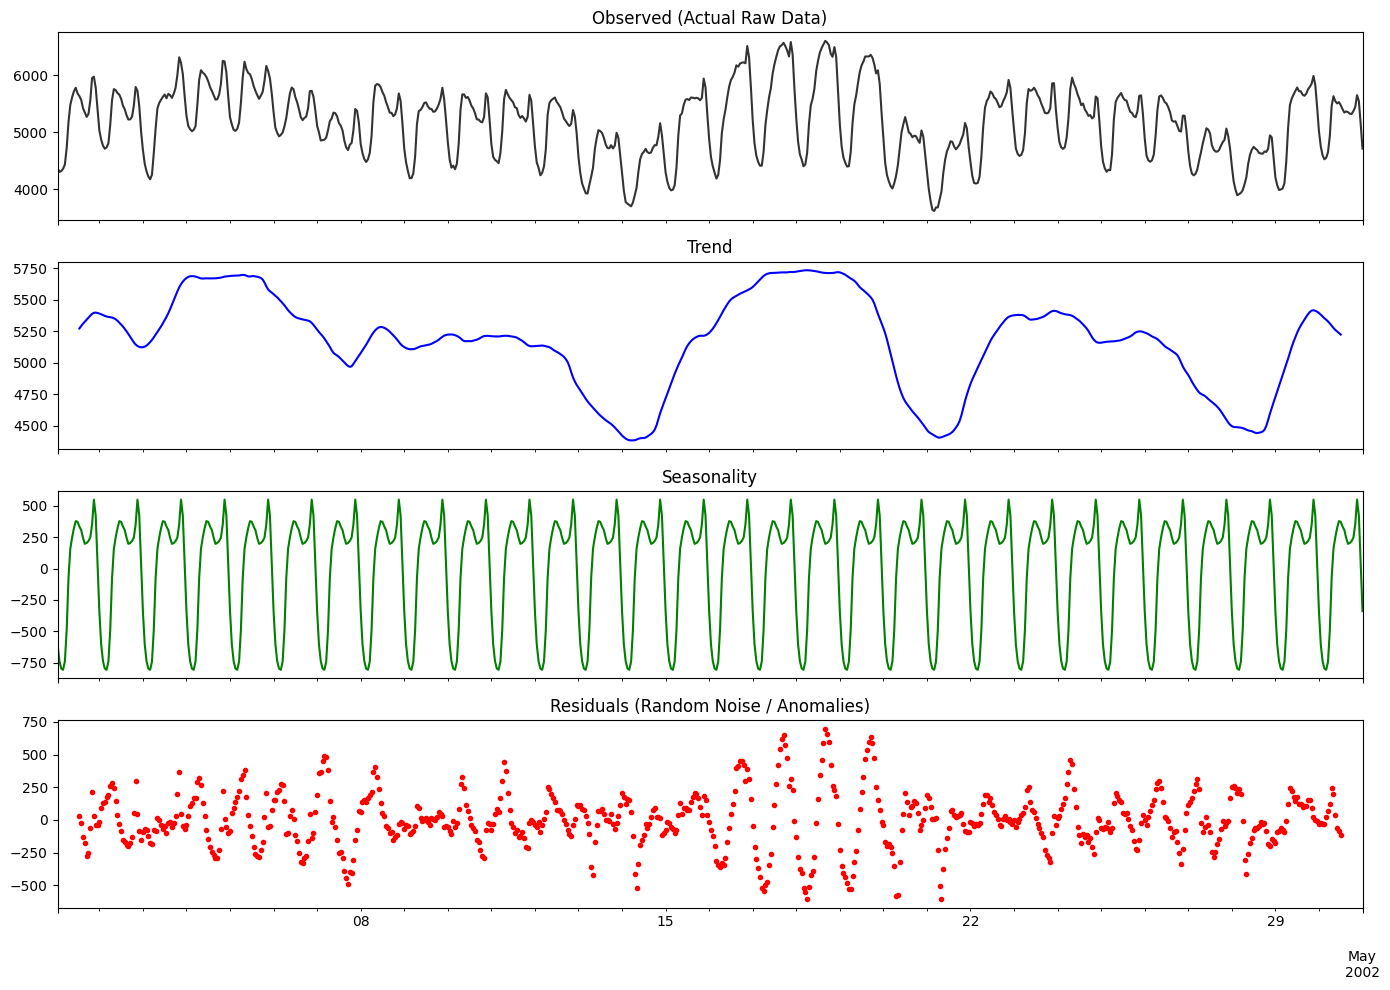

In [ ]:
from statsmodels.tsa.seasonal import seasonal_decompose

# We set period=24 because our data is hourly and repeats every day
decomp_sample = df['PJMW_MW'].iloc[:720]
decomposition = seasonal_decompose(decomp_sample, model='additive', period=24)

# Plotting the components
fig, axes = plt.subplots(4, 1, figsize=(14, 10), sharex=True)

decomposition.observed.plot(ax=axes[0], color='black', alpha=0.8, title='Observed (Actual Raw Data)')
decomposition.trend.plot(ax=axes[1], color='blue', title='Trend')
decomposition.seasonal.plot(ax=axes[2], color='green', title='Seasonality')
decomposition.resid.plot(ax=axes[3], color='red', style='.', title='Residuals (Random Noise / Anomalies)')

plt.tight_layout()
plt.show()

The decomposition confirms that the PJM grid is heavily governed by strong daily seasonal rhythms. However, because the Trend shifts dynamically across weeks and the Residuals show clear anomaly spikes, a simple seasonal average will not be enough to forecast accurately. Our model must be flexible enough to adapt to moving trends and sudden residual shifts to predict the next 30 days effectively.

## Train-Test split

In [ ]:
# Define the cutoff point: exactly 365 days before the maximum date in the dataset
test_cutoff = df.index.max() - pd.Timedelta(days=365)

In [ ]:
# Split the data chronologically
train = df[df.index <= test_cutoff].copy()
test = df[df.index > test_cutoff].copy()

In [ ]:
y_train = train['PJMW_MW']
y_test = test['PJMW_MW']

print(f"Training Series Shape: {y_train.shape}")
print(f"Testing Series Shape: {y_test.shape}")

Training Series Shape: (134472,)
Testing Series Shape: (8760,)


In [ ]:
y_train.head()

,PJMW_MW
2002-04-01 01:00:00,4374.0
2002-04-01 02:00:00,4306.0
2002-04-01 03:00:00,4322.0
2002-04-01 04:00:00,4359.0
2002-04-01 05:00:00,4436.0


In [ ]:
y_test.head()

,PJMW_MW
2017-08-03 01:00:00,5170.0
2017-08-03 02:00:00,4948.0
2017-08-03 03:00:00,4700.0
2017-08-03 04:00:00,4606.0
2017-08-03 05:00:00,4580.0


# Model Building

In [ ]:
import numpy as np
from sklearn.metrics import root_mean_squared_error, mean_absolute_error,mean_absolute_percentage_error

## 1. Simple Naive Model

The simple naive model acts as baseline model. The naive model basically predicts that the energy consumption on next day is as same as today.

In [ ]:
# Last value
last_val=y_train.iloc[-1]

In [ ]:
last_val

np.float64(5591.0)

In [ ]:
y_pred_simple=np.full((len(y_test),),last_val)

In [ ]:
# Metrics
mae_simple = mean_absolute_error(y_test, y_pred_simple)
rmse_simple = root_mean_squared_error(y_test, y_pred_simple)
mape_simple = mean_absolute_percentage_error(y_test, y_pred_simple)*100

In [ ]:
print("--- Model 1: Simple Naive Results ---")
print(f"MAE : {mae_simple:.2f} MW")
print(f"RMSE: {rmse_simple:.2f} MW")
print(f"MAPE: {mape_simple:.2f} %")

--- Model 1: Simple Naive Results ---
MAE : 785.39 MW
RMSE: 999.68 MW
MAPE: 13.87 %


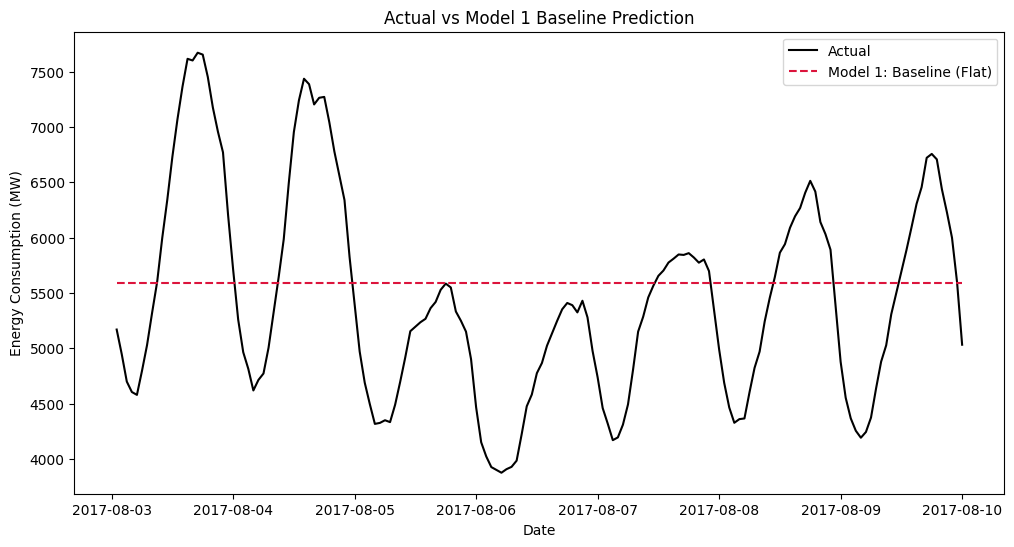

In [ ]:
# Naive Baseline vs Actual
plt.figure(figsize=(12,6))
sns.lineplot(x=y_test.index[:168], y=y_test[:168], label='Actual', color='black')
sns.lineplot(x=y_test.index[:168], y=y_pred_simple[:168], label='Model 1: Baseline (Flat)', color='crimson', linestyle='--')
plt.legend()
plt.xlabel('Date')
plt.ylabel('Energy Consumption (MW)')
plt.title('Actual vs Model 1 Baseline Prediction')
plt.show()

## 2. Seasonal Naive Model

Since we saw that a weekly lookback ($24 \text{ hours} \times 7 \text{ days} = 168 \text{ hours}$) captures both the hour of the day and the weekday/weekend shifts best, our model will copy the last 168 hours of the training set and repeat that pattern over and over to fill the 365 days of the test set.

In [ ]:
# last week pattern
last_week_pattern=y_train.iloc[-168:].values

In [ ]:
last_week_pattern

array([5097., 4881., 4626., 4587., 4589., 4763., 5005., 5359., 5545.,
       5842., 6105., 6470., 6819., 7029., 7177., 7223., 7283., 7232.,
       7049., 6885., 6750., 6619., 6117., 5708., 5229., 4924., 4803.,
       4752., 4754., 4903., 5173., 5492., 5708., 5914., 6118., 6273.,
       6355., 6489., 6419., 6388., 6334., 6278., 6178., 6067., 5977.,
       5842., 5430., 5005., 4801., 4547., 4397., 4250., 4158., 4257.,
       4295., 4426., 4641., 4767., 4884., 4957., 4964., 5014., 5061.,
       5140., 5284., 5335., 5348., 5288., 5086., 5031., 4709., 4450.,
       4093., 3898., 3836., 3698., 3722., 3757., 3808., 3884., 4193.,
       4321., 4677., 4920., 5111., 5359., 5524., 5793., 5990., 6221.,
       6208., 6036., 5898., 5827., 5413., 4980., 4561., 4366., 4240.,
       4131., 4177., 4362., 4551., 4813., 5167., 5483., 5834., 6244.,
       6510., 6763., 6960., 7134., 7260., 7314., 7224., 7027., 6711.,
       6471., 5903., 5309., 4920., 4692., 4451., 4405., 4362., 4552.,
       4799., 5107.,

In [ ]:
# Repeat this 168-hour pattern to match the length of y_test
num_repeats = int(np.ceil(len(y_test) / 168))
y_pred_snaive = np.tile(last_week_pattern, num_repeats)[:len(y_test)]

In [ ]:
# Metrics
mae_snaive = mean_absolute_error(y_test, y_pred_snaive)
rmse_snaive = root_mean_squared_error(y_test, y_pred_snaive)
mape_snaive = mean_absolute_percentage_error(y_test, y_pred_snaive) * 100

In [ ]:
print("--- Model 2: Seasonal Naive Results ---")
print(f"MAE : {mae_snaive:.2f} MW")
print(f"RMSE: {rmse_snaive:.2f} MW")
print(f"MAPE: {mape_snaive:.2f} %")

--- Model 2: Seasonal Naive Results ---
MAE : 792.11 MW
RMSE: 1045.92 MW
MAPE: 13.45 %


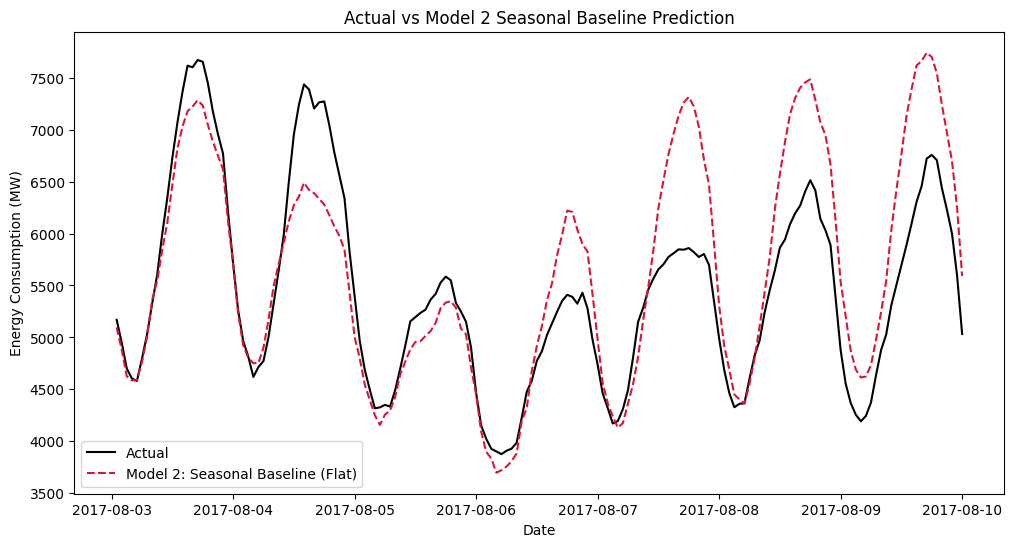

In [ ]:
# Seasonal Naive Baseline vs Actual
plt.figure(figsize=(12,6))
sns.lineplot(x=y_test.index[:168], y=y_test[:168], label='Actual', color='black')
sns.lineplot(x=y_test.index[:168], y=y_pred_snaive[:168], label='Model 2: Seasonal Baseline (Flat)', color='crimson', linestyle='--')
plt.legend()
plt.xlabel('Date')
plt.ylabel('Energy Consumption (MW)')
plt.title('Actual vs Model 2 Seasonal Baseline Prediction')
plt.show()

## 3. Exponential Smoothing (Holt-Winters)

In [ ]:
from statsmodels.tsa.api import ExponentialSmoothing

In [ ]:
hw_model=ExponentialSmoothing(
    # last 28 days data
    y_train.iloc[-672:],
    trend='add',
    seasonal='add',
    seasonal_periods=24
).fit()

/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/holtwinters/model.py:903: ConvergenceWarning: Optimization failed to converge. Check mle_retvals.
  warnings.warn(


In [ ]:
y_pred_hw=hw_model.forecast(steps=len(y_test))

In [ ]:
# Metrics
mae_hw = mean_absolute_error(y_test, y_pred_hw)
rmse_hw = root_mean_squared_error(y_test, y_pred_hw)
mape_hw = mean_absolute_percentage_error(y_test, y_pred_hw) * 100

In [ ]:
print("--- Model 3: Exponential Smoothing Results ---")
print(f"MAE : {mae_hw:.2f} MW")
print(f"RMSE: {rmse_hw:.2f} MW")
print(f"MAPE: {mape_hw:.2f} %")

--- Model 3: Exponential Smoothing Results ---
MAE : 647269.20 MW
RMSE: 747501.96 MW
MAPE: 11571.57 %


Model 3 (Exponential Smoothing) failed to converge and produced extreme errors due to numerical overflow. Classic Holt-Winters models struggle mathematically with high-frequency hourly data when estimating a large number of seasonal parameters simultaneously. This failure highlights the necessity of moving to advanced models like ARIMA which are inherently built to handle complex, overlapping seasonal cycles.


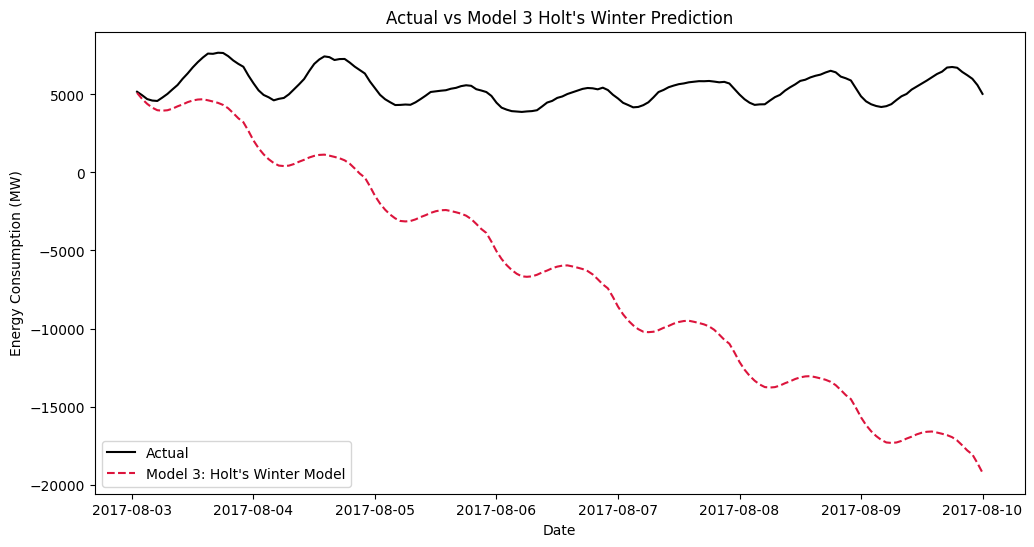

In [ ]:
# Holts Winter vs Actual
plt.figure(figsize=(12,6))
sns.lineplot(x=y_test.index[:168], y=y_test[:168], label='Actual', color='black')
sns.lineplot(x=y_test.index[:168], y=y_pred_hw[:168], label="Model 3: Holt's Winter Model", color='crimson', linestyle='--')
plt.legend()
plt.xlabel('Date')
plt.ylabel('Energy Consumption (MW)')
plt.title("Actual vs Model 3 Holt's Winter Prediction")
plt.show()

## 4. ARIMA Model

In [ ]:
y_train_diff=y_train.diff(1).diff(24).dropna()

In [ ]:
print("--- Original Training Data ---")
print(y_train.head(3))

--- Original Training Data ---
2002-04-01 01:00:00    4374.0
2002-04-01 02:00:00    4306.0
2002-04-01 03:00:00    4322.0
Freq: h, Name: PJMW_MW, dtype: float64


In [ ]:
print("--- Differenced Training Data ---")
print(y_train_diff.head(3))

--- Differenced Training Data ---
2002-04-02 02:00:00   -37.0
2002-04-02 03:00:00   -71.0
2002-04-02 04:00:00   -13.0
Freq: h, Name: PJMW_MW, dtype: float64


In [ ]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

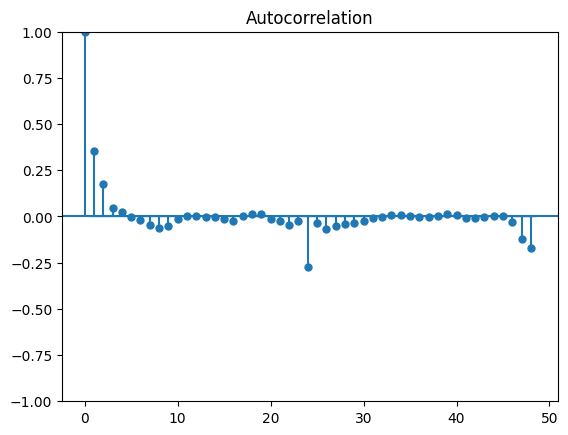

In [ ]:
# acf plot
plot_acf(y_train_diff,lags=48)
plt.show()

Upon observing the acf plot, we can determine q=2.

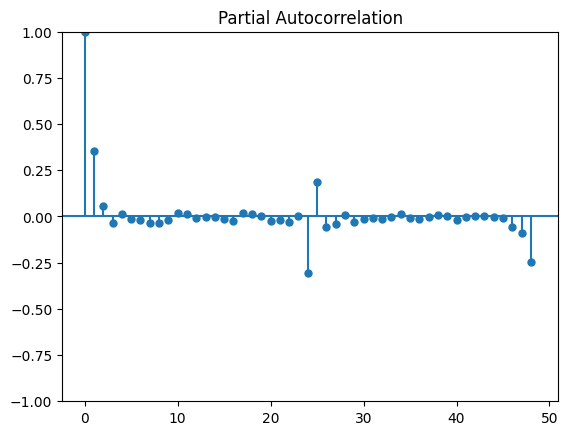

In [ ]:
# pacf plot
plot_pacf(y_train_diff,lags=48)
plt.show()

Upon observing the pacf plot we can determine p=1

In [ ]:
from statsmodels.tsa.arima.model import ARIMA

In [ ]:
arima_model=ARIMA(y_train_diff,order=(1,0,2)).fit()

In [ ]:
pred_double_diff = arima_model.forecast(steps=len(y_test))

In [ ]:
# Revert the double-differencing step-by-step using historical context
history = list(y_train.values)
y_pred_arima = []

In [ ]:
for diff_val in pred_double_diff:
    # Reconstruct the value using the mathematical inverse formula
    actual_val = diff_val + history[-1] + history[-24] - history[-25]
    y_pred_arima.append(actual_val)
    history.append(actual_val)

In [ ]:
# performance metrics
mae_arima = mean_absolute_error(y_test, y_pred_arima)
rmse_arima = root_mean_squared_error(y_test, y_pred_arima)
mape_arima = mean_absolute_percentage_error(y_test, y_pred_arima) * 100

In [ ]:
print("--- Model 4: ARIMA Results ---")
print(f"MAE : {mae_arima:.2f} MW")
print(f"RMSE: {rmse_arima:.2f} MW")
print(f"MAPE: {mape_arima:.2f} %")

--- Model 4: ARIMA Results ---
MAE : 1981.80 MW
RMSE: 2241.73 MW
MAPE: 36.48 %


With a MAPE of ~36.5%, standard ARIMA performed significantly worse than both your Naive and Seasonal Naive baselines.Standard ARIMA only tracks short-term relationships between consecutive hours ($t$ vs $t-1$). It does not have built-in memory to automatically track a 24-hour cycle.

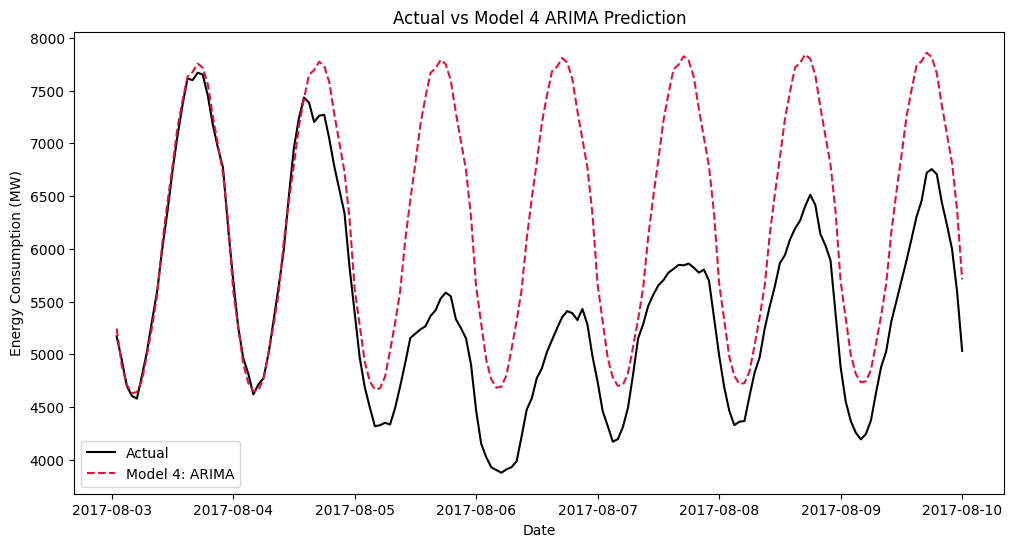

In [ ]:
# ARIMA vs Actual
plt.figure(figsize=(12,6))
sns.lineplot(x=y_test.index[:168], y=y_test[:168], label='Actual', color='black')
sns.lineplot(x=y_test.index[:168], y=y_pred_arima[:168], label='Model 4: ARIMA', color='crimson', linestyle='--')
plt.legend()
plt.xlabel('Date')
plt.ylabel('Energy Consumption (MW)')
plt.title('Actual vs Model 4 ARIMA Prediction')
plt.show()

## 5. SARIMA Model

In [ ]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

In [ ]:
y_train_small=y_train.iloc[-2160:]

In [ ]:
sarima_model=SARIMAX(y_train_small,order=(1,1,1),seasonal_order=(1,1,1,24)).fit()

In [ ]:
y_pred_sarima = sarima_model.forecast(steps=len(y_test))

In [ ]:
# performance metrics
mae_sarima = mean_absolute_error(y_test, y_pred_sarima)
rmse_sarima = root_mean_squared_error(y_test, y_pred_sarima)
mape_sarima = mean_absolute_percentage_error(y_test, y_pred_sarima) * 100

In [ ]:
print("--- Model 5: SARIMA Results ---")
print(f"MAE : {mae_sarima:.2f} MW")
print(f"RMSE: {rmse_sarima:.2f} MW")
print(f"MAPE: {mape_sarima:.2f} %")

--- Model 5: SARIMA Results ---
MAE : 836.97 MW
RMSE: 1047.66 MW
MAPE: 14.93 %


In [ ]:
print(f"Model AIC: {sarima_model.aic}")
print(f"Model BIC: {sarima_model.bic}")

Model AIC: 24402.199775492285
Model BIC: 24430.5308851206


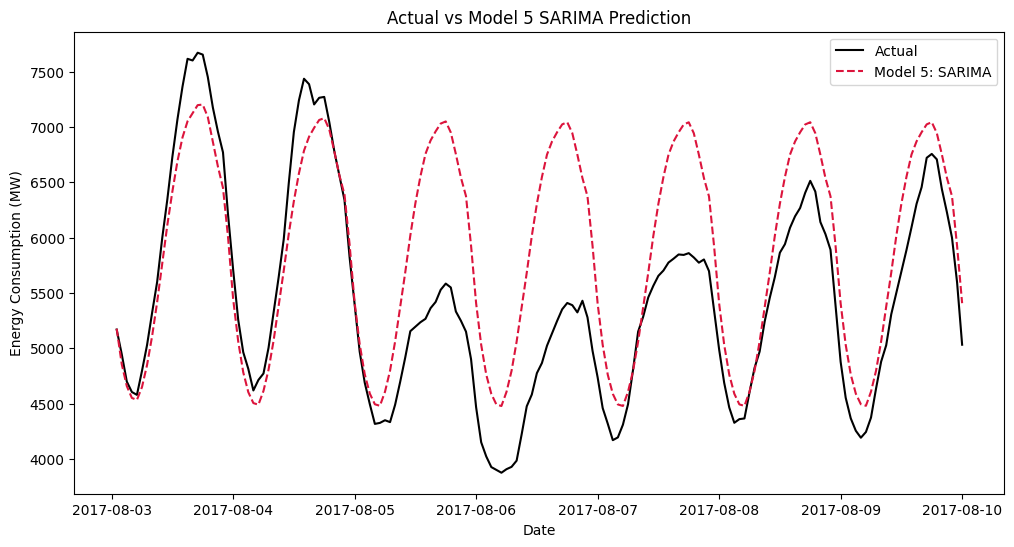

In [ ]:
# SARIMA vs Actual
plt.figure(figsize=(12,6))
sns.lineplot(x=y_test.index[:168], y=y_test[:168], label='Actual', color='black')
sns.lineplot(x=y_test.index[:168], y=y_pred_sarima[:168], label='Model 5: SARIMA', color='crimson', linestyle='--')
plt.legend()
plt.xlabel('Date')
plt.ylabel('Energy Consumption (MW)')
plt.title('Actual vs Model 5 SARIMA Prediction')
plt.show()

## 6. SARIMAX Model

In [ ]:
!pip install holidays

In [ ]:
import holidays

In [ ]:
# function to create additional features
def create_advanced_features(data_index):
    features = pd.DataFrame(index=data_index)

    # 1. Detailed Hourly Features (Night Baseline is omitted)
    features['hr_morning_ramp'] = ((features.index.hour >= 6) & (features.index.hour <= 9)).astype(int)
    features['hr_midday'] = ((features.index.hour >= 10) & (features.index.hour <= 14)).astype(int)
    features['hr_evening_peak'] = ((features.index.hour >= 15) & (features.index.hour <= 22)).astype(int)

    # 2. Weekly Feature
    features['is_weekend'] = (features.index.dayofweek >= 5).astype(int)

    # 3. Seasonal Features (Spring is omitted)
    features['is_winter'] = features.index.month.isin([12, 1, 2]).astype(int)
    features['is_summer'] = features.index.month.isin([6, 7, 8]).astype(int)
    features['is_autumn'] = features.index.month.isin([9, 10, 11]).astype(int)

    # 4. Holiday Feature
    us_holidays = holidays.US(years=data_index.year.unique())
    features['is_holiday'] = pd.Series(features.index.date, index=features.index).isin(us_holidays).astype(int)

    return features

In [ ]:
# Build the advanced matrices
X_train_exog_adv = create_advanced_features(y_train_small.index)
X_test_exog_adv = create_advanced_features(y_test.index)

In [ ]:
# Fit the model using both the raw target data and the training features
sarimax_with_features = SARIMAX(y_train_small,
                                exog=X_train_exog_adv,
                                order=(1, 1, 1),
                                seasonal_order=(1, 1, 1, 24)).fit()

In [ ]:
# Forecast by providing the matching future features
y_pred_sarimax = sarimax_with_features.forecast(steps=len(y_test),
                                                exog=X_test_exog_adv)

In [ ]:
# Calculate the updated metrics
mae_sarimax = mean_absolute_error(y_test, y_pred_sarimax)
mape_sarimax = mean_absolute_percentage_error(y_test, y_pred_sarimax) * 100
rmse_sarimax = root_mean_squared_error(y_test, y_pred_sarimax)

In [ ]:
print("--- Model 6: SARIMAX Results ---")
print(f"MAE : {mae_sarimax:.2f} MW")
print(f"RMSE:{rmse_sarimax:.2f} MW")
print(f"MAPE: {mape_sarimax:.2f} %")

--- Model 6: SARIMAX Results ---
MAE : 799.14 MW
RMSE:1017.74 MW
MAPE: 14.09 %


In [ ]:
print(f"Model AIC: {sarimax_with_features.aic}")
print(f"Model BIC: {sarimax_with_features.bic}")

Model AIC: 24413.914668316826
Model BIC: 24487.57555335044


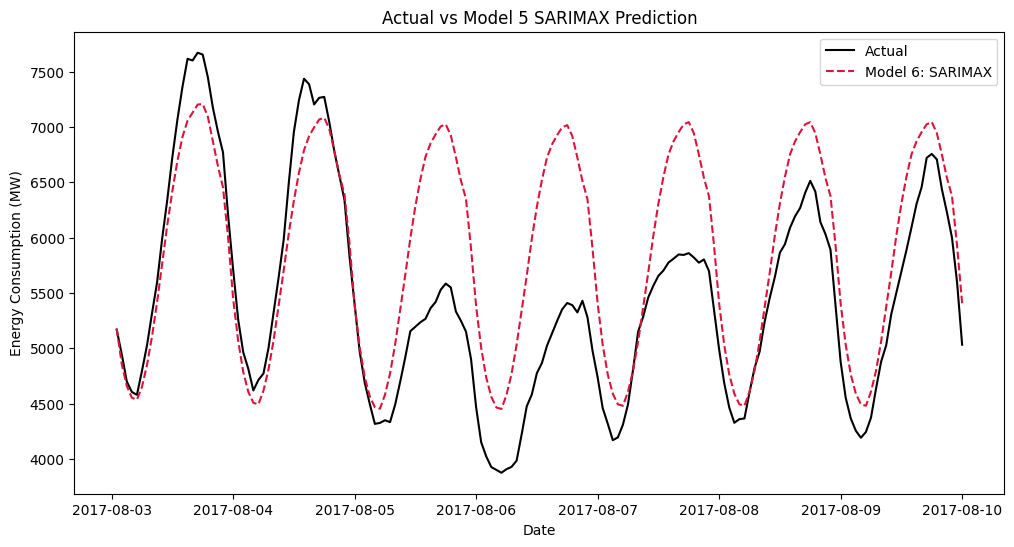

In [ ]:
# SARIMAX vs Actual
plt.figure(figsize=(12,6))
sns.lineplot(x=y_test.index[:168], y=y_test[:168], label='Actual', color='black')
sns.lineplot(x=y_test.index[:168], y=y_pred_sarimax[:168], label='Model 6: SARIMAX', color='crimson', linestyle='--')
plt.legend()
plt.xlabel('Date')
plt.ylabel('Energy Consumption (MW)')
plt.title('Actual vs Model 5 SARIMAX Prediction')
plt.show()

## Analysis

## Model Performance Leaderboard

<table style="width:100%; border-collapse: collapse; margin: 25px 0; font-size: 0.95em; font-family: sans-serif; min-width: 400px; box-shadow: 0 0 20px rgba(0, 0, 0, 0.15);">
    <thead>
        <tr style="background-color: #1f2d3d; color: #ffffff; text-align: left; font-weight: bold;">
            <th style="padding: 12px 15px;">Model Configuration</th>
            <th style="padding: 12px 15px;">MAE (MW)</th>
            <th style="padding: 12px 15px;">RMSE (MW)</th>
            <th style="padding: 12px 15px;">MAPE (%)</th>
        </tr>
    </thead>
    <tbody>
        <tr style="border-bottom: 1px solid #dddddd;">
            <td style="padding: 12px 15px; font-weight: bold; color: #555;">Model 1: Naive Baseline</td>
            <td style="padding: 12px 15px;">785.39</td>
            <td style="padding: 12px 15px;">999.68</td>
            <td style="padding: 12px 15px;">13.87 %</td>
        </tr>
        <tr style="border-bottom: 1px solid #dddddd;">
            <td style="padding: 12px 15px; font-weight: bold; color: #555;">Model 2: Seasonal Naive Baseline</td>
            <td style="padding: 12px 15px;">792.11</td>
            <td style="padding: 12px 15px;">1045.92</td>
            <td style="padding: 12px 15px;">13.45 %</td>
        </tr>
        <tr style="border-bottom: 1px solid #dddddd;">
            <td style="padding: 12px 15px; font-weight: bold; color: #cc0000;">Model 3: Holt-Winters Exponential Smoothing</td>
            <td style="padding: 12px 15px;">647,269.20</td>
            <td style="padding: 12px 15px;">747,501.96</td>
            <td style="padding: 12px 15px; color: #cc0000; font-weight: bold;">11,571.57 %</td>
        </tr>
        <tr style="border-bottom: 1px solid #dddddd;">
            <td style="padding: 12px 15px; font-weight: bold; color: #555;">Model 4: Basic ARIMA(1,1,1)</td>
            <td style="padding: 12px 15px;">1,981.80</td>
            <td style="padding: 12px 15px;">2,241.73</td>
            <td style="padding: 12px 15px;">36.48 %</td>
        </tr>
        <tr style="border-bottom: 1px solid #dddddd;">
            <td style="padding: 12px 15px; font-weight: bold; color: #555;">Model 5: SARIMA(1,1,1)x(1,1,1,24)</td>
            <td style="padding: 12px 15px;">836.97</td>
            <td style="padding: 12px 15px;">1,047.66</td>
            <td style="padding: 12px 15px;">14.93 %</td>
        </tr>
        <tr style="background-color: #f3fff3; border-bottom: 2px solid #009879;">
            <td style="padding: 12px 15px; font-weight: bold; color: #009879;">🏆 Model 6: Advanced SARIMAX</td>
            <td style="padding: 12px 15px; font-weight: bold;">799.14</td>
            <td style="padding: 12px 15px; font-weight: bold;">1,017.74</td>
            <td style="padding: 12px 15px; font-weight: bold; color: #009879;">14.09 %</td>
        </tr>
    </tbody>
</table>

# Model Deployment

In [ ]:
import pickle

In [ ]:
with open('model.pkl', 'wb') as file:
    pickle.dump(sarimax_with_features, file)